# Application 3C — OJ purchases and SVM score cutoffs

**Question:** How should unequal error costs change an SVM decision?

The 1,070 OJ records label Minute Maid (MM) as 1 and Citrus Hill (CH) as 0.
Use six price/discount/promotion inputs, excluding the purchase label.
An SVM returns a real score f(x), **not a probability**; predict MM at $f(x)\ge t$.

Training CV selects C/gamma and the best SVM family by balanced accuracy (mean class recall).
Separately tune logistic as a comparison; it may outperform SVM. Validation selects the chosen SVM's
cutoff for teaching costs FP=1, FN=3. A probability cutoff 1/4 is not a score cutoff.

Use stratified 60/20/20 splits, seed 23, and freeze decisions before test.
Repeated stores/weeks mean random splitting does not establish future-week or new-store performance.
Data are bundled locally. See [lecture](03_support_vector_machines.pdf) and [solution](Solutions/03_C_oj_score_thresholds_solution.pdf).

## 1. Load the bundled CSV and reserve rows

The loader finds `data/OJ.csv` from the notebook folder or course ancestors; `read_csv` creates the table.
Check 653 CH/417 MM labels and no exported index column. Stratified splitting preserves class proportions.
`describe` summarizes training scales; store/week ranges audit the split. Use only the six specified predictors.
Source: [ISLP OJ documentation](https://intro-stat-learning.github.io/ISLP/datasets/OJ.html).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, confusion_matrix, roc_auc_score

# Find the bundled data from the notebook folder or a course ancestor.
locations = ("", "data", "FocusedContent/data", "StatisticalLearning/FocusedContent/data")
candidates = [base / folder / "OJ.csv" for base in (Path.cwd(), *Path.cwd().parents)
              for folder in locations]
path = next((candidate for candidate in candidates if candidate.is_file()), None)
if path is None:
    raise FileNotFoundError("Missing OJ.csv. Keep the FocusedContent/data folder with the notebooks; "
                            "in Colab, upload the CSV to /content/data or /content.")
data = pd.read_csv(path)
assert len(data) == 1070 and data["Purchase"].value_counts().to_dict() == {"CH": 653, "MM": 417}
features = ["PriceCH", "PriceMM", "DiscCH", "DiscMM", "SpecialCH", "SpecialMM"]
assert data[features].notna().all().all()
X = data[features].to_numpy()
y = (data["Purchase"] == "MM").astype(int).to_numpy()
train_valid_ids, test_ids = train_test_split(np.arange(len(y)), test_size=0.2, random_state=23, stratify=y)
train_ids, valid_ids = train_test_split(train_valid_ids, test_size=0.25, random_state=23, stratify=y[train_valid_ids])
assert set(train_ids).isdisjoint(valid_ids) and set(train_ids).isdisjoint(test_ids)
assert set(valid_ids).isdisjoint(test_ids)
X_train, y_train = X[train_ids], y[train_ids]
X_valid, y_valid = X[valid_ids], y[valid_ids]
X_test, y_test = X[test_ids], y[test_ids]
print("Train / validation / test:", len(train_ids), len(valid_ids), len(test_ids))
print("Training [CH, MM] counts:", np.bincount(y_train))
display(data.iloc[train_ids][features].describe().loc[["mean", "std", "min", "max"]])
for name, ids in [("train", train_ids), ("validation", valid_ids), ("test", test_ids)]:
    rows = data.iloc[ids]
    print(name, "stores:", sorted(rows["StoreID"].unique()),
          "week range:", (rows["WeekofPurchase"].min(), rows["WeekofPurchase"].max()))

Train / validation / test: 642 214 214
Training [CH, MM] counts: [392 250]


,PriceCH,PriceMM,DiscCH,DiscMM,SpecialCH,SpecialMM
mean,1.868505,2.086121,0.048879,0.121869,0.137072,0.165109
std,0.101202,0.134832,0.116005,0.212614,0.344191,0.371568
min,1.690000,1.690000,0.000000,0.000000,0.000000,0.000000
max,2.090000,2.290000,0.500000,0.800000,1.000000,1.000000


train stores: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(7)] week range: (np.int64(227), np.int64(278))
validation stores: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(7)] week range: (np.int64(228), np.int64(278))
test stores: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(7)] week range: (np.int64(227), np.int64(277))


## 2. Select settings by training CV

`make_pipeline(StandardScaler(),estimator)` refits scaling (including binary inputs) within each fold.
Linear SVC fits a hyperplane; RBF uses nonlinear distance similarity. Logistic supplies comparison scores.
`StratifiedKFold` and `cross_val_score` evaluate five held-out training groups by balanced accuracy.

Search C=0.01,0.1,1,10 and RBF gamma=0.01,0.1,1,10. Select within each family, then between SVM families;
ties follow table order. Refit winners on 642 training rows. Search scores are not independent evaluations.
`classes_` checks that positive scores favor MM. C≤10 and tolerance 0.001 keep runtime manageable;
very large C can slow nearly degenerate fits.

In [2]:
def build_model(family, C, gamma=1):
    if family == "Logistic":
        estimator = LogisticRegression(C=C, max_iter=2000, tol=1e-8)
    else:
        estimator = SVC(kernel="linear" if family == "Linear SVM" else "rbf",
                        C=C, gamma=gamma, tol=1e-3)
    return make_pipeline(StandardScaler(), estimator)

folds = list(StratifiedKFold(5, shuffle=True, random_state=23).split(X_train, y_train))
cv_rows = []
for family in ["Logistic", "Linear SVM", "RBF SVM"]:
    for C in [0.01, 0.1, 1, 10]:
        for gamma in [0.01, 0.1, 1, 10] if family == "RBF SVM" else [1]:
            scores = cross_val_score(build_model(family, C, gamma), X_train, y_train,
                                     cv=folds, scoring="balanced_accuracy")
            cv_rows.append({"family": family, "C": C, "gamma": gamma,
                            "CV balanced accuracy": scores.mean(), "fold SD": scores.std(ddof=1)})
cv_results = pd.DataFrame(cv_rows)
best_rows = cv_results.loc[cv_results.groupby("family", sort=False)["CV balanced accuracy"].idxmax()]
svm_rows = best_rows[best_rows["family"] != "Logistic"]
selected_name = svm_rows.loc[svm_rows["CV balanced accuracy"].idxmax(), "family"]
models = {}
for _, row in best_rows.iterrows():
    models[row["family"]] = build_model(row["family"], float(row["C"]), float(row["gamma"])).fit(X_train, y_train)
    np.testing.assert_array_equal(models[row["family"]].classes_, [0, 1])
selected = models[selected_name]
display(best_rows.reset_index(drop=True))
print("Frozen SVM for threshold selection:", selected_name)

,family,C,gamma,CV balanced accuracy,fold SD
0,Logistic,0.1,1.0,0.622797,0.040733
1,Linear SVM,1.0,1.0,0.582513,0.061602
2,RBF SVM,1.0,0.1,0.630041,0.038111


Frozen SVM for threshold selection: RBF SVM


## 3. Search every validation decision pattern

Plot scores by actual class. FP means predicting MM for CH; FN means predicting CH for MM.
Minimize $(FP+3FN)/214$; zero need not be optimal.

With score ≥ cutoff, distinct scores define decision patterns. Search −infinity (all positive),
every distinct score after the smallest, and +infinity (all negative). This includes all patterns,
even with tied scores. Cost ties choose the largest cutoff, favoring fewer positives.
`confusion_matrix(labels=[0,1]).ravel()` gives TN,FP,FN,TP.
The plot omits infinite cutoffs, but the table and search include them.

Validation decision patterns: 65
Frozen score threshold: -1.0014161355586264
Validation cost per row: 0.5467289719626168


,threshold,FP,FN,total cost
0,-inf,130,0,130
64,inf,0,84,252


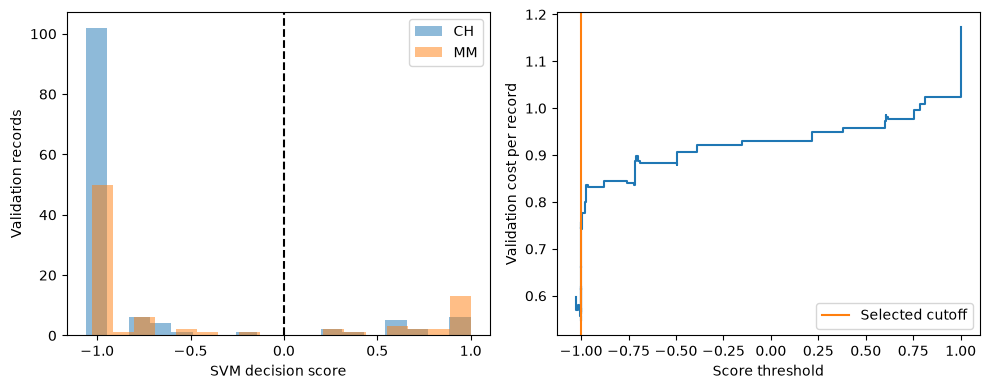

In [3]:
validation_score = selected.decision_function(X_valid)
unique_scores = np.unique(validation_score)
thresholds = np.r_[-np.inf, unique_scores[1:], np.inf]
threshold_rows = []
for threshold in thresholds:
    prediction = (validation_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, prediction, labels=[0, 1]).ravel()
    threshold_rows.append({"threshold": threshold, "FP": fp, "FN": fn, "total cost": fp + 3*fn})
threshold_results = pd.DataFrame(threshold_rows)
minimum_cost = threshold_results["total cost"].min()
best_threshold = threshold_results.loc[threshold_results["total cost"] == minimum_cost, "threshold"].max()
assert len(thresholds) == len(unique_scores) + 1
print("Validation decision patterns:", len(thresholds))
print("Frozen score threshold:", best_threshold)
print("Validation cost per row:", minimum_cost / len(y_valid))
display(threshold_results.loc[[0, len(threshold_results)-1]])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label, name in [(0, "CH"), (1, "MM")]:
    axes[0].hist(validation_score[y_valid == label], bins=18, alpha=0.5, label=name)
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set(xlabel="SVM decision score", ylabel="Validation records")
axes[0].legend()
finite = np.isfinite(threshold_results["threshold"])
axes[1].step(threshold_results.loc[finite, "threshold"],
             threshold_results.loc[finite, "total cost"] / len(y_valid), where="pre")
if np.isfinite(best_threshold):
    axes[1].axvline(best_threshold, color="tab:orange", label="Selected cutoff")
    axes[1].legend()
axes[1].set(xlabel="Score threshold", ylabel="Validation cost per record")
plt.tight_layout(); plt.show()

## 4. Why the cutoff is not 1/4

For a genuine probability p, MM costs $1-p$ in expectation and CH costs $3p$;
choose MM at $p\ge1/4$. SVM scores may be negative or exceed 1. An arbitrary sigmoid does not calibrate them.
Here validation selects a score cutoff directly; no Brier/log loss is reported for raw scores.

Keep the SVM fit unchanged: refitting can alter score magnitudes and invalidate the cutoff.
Probability calibration is an optional topic in the full lecture.

## 5. Evaluate frozen test policies

Compare tuned logistic and both SVM families at zero with the training-majority baseline.
Then compare only the selected SVM at zero versus its validation cutoff.
ROC AUC measures score ranking without a cutoff or probabilities. Accuracy is the correct fraction;
precision=TP/(TP+FP), recall=TP/(TP+FN); undefined values are explicitly reported as zero.

**Explain:** Did lower cost sacrifice accuracy? Why is 1/4 not the score cutoff?
What do overlapping stores/weeks imply for generalization claims? Do not revise costs or cutoffs from test results.

In [4]:
majority = int(np.bincount(y_train).argmax())
test_rows = [{"model": "Majority baseline", "accuracy": np.mean(y_test == majority),
              "balanced accuracy": balanced_accuracy_score(y_test, np.full(len(y_test), majority)), "ROC AUC": 0.5}]
for name, model in models.items():
    score = model.decision_function(X_test)
    pred = (score >= 0).astype(int)
    test_rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                     "balanced accuracy": balanced_accuracy_score(y_test, pred), "ROC AUC": roc_auc_score(y_test, score)})
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results)
test_score = selected.decision_function(X_test)
policy_rows = []
for name, threshold in [("Zero score", 0), ("Validation-selected", best_threshold)]:
    pred = (test_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    policy_rows.append({"policy": name, "threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                       "accuracy": accuracy_score(y_test, pred), "balanced accuracy": balanced_accuracy_score(y_test, pred),
                       "precision": precision_score(y_test, pred, zero_division=0),
                       "recall": recall_score(y_test, pred, zero_division=0), "cost per record": (fp+3*fn)/len(y_test)})
policy_results = pd.DataFrame(policy_rows).set_index("policy")
display(policy_results)
chosen_prediction = (test_score >= best_threshold).astype(int)
display(pd.DataFrame(confusion_matrix(y_test, chosen_prediction, labels=[0, 1]),
                     index=["Actual CH", "Actual MM"], columns=["Predicted CH", "Predicted MM"]))

,accuracy,balanced accuracy,ROC AUC
model,,,
Majority baseline,0.612150,0.500000,0.500000
Logistic,0.640187,0.593534,0.650878
Linear SVM,0.649533,0.576888,0.648027
RBF SVM,0.677570,0.619654,0.673135


,threshold,TN,FP,FN,TP,accuracy,balanced accuracy,precision,recall,cost per record
policy,,,,,,,,,,
Zero score,0.000000,115,16,53,30,0.67757,0.619654,0.652174,0.361446,0.817757
Validation-selected,-1.001416,18,113,1,82,0.46729,0.562678,0.420513,0.987952,0.542056


,Predicted CH,Predicted MM
Actual CH,18,113
Actual MM,1,82


**Documentation reference:** [scikit-learn 1.8 SVM guide](https://scikit-learn.org/1.8/modules/svm.html).